# Week 3: Forward and Backward Selection, PCR, and PLSR
**Victor Vasquez Gil** | Boston University | Integrated Capstone


## 1. Research Question

Can I explain Lending Club interest rates with fewer predictors or components without giving up much predictive accuracy?

This continues the interest-rate analysis from Week 2. Since the interest rate is a continuous pricing outcome, linear regression is the natural fit here. Note that this is a companion analysis for my credit-risk capstone focused on pricing, not a default classifier—Week 4 handles the binary loan outcome.

In this notebook, I compare two different paths to model simplification:
* **Feature Selection:** Forward and backward selection retain the original features.
* **Dimension Reduction:** Principal Component Regression (PCR) and Partial Least Squares Regression (PLSR) construct new composite features.

My expectation going in is that simpler models should be easier to interpret and maintain, though dropping variables or components won't automatically guarantee better out-of-sample predictions.

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys, json, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1


In [3]:
SEED = 42
SAMPLE_SIZE = 50_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701  # Accepted-loans version 3; prevents accidental use of a partial export.
CV_FOLDS = 5
N_JOBS = 1
MODEL_TRAIN_SIZE = 8_000  # Weeks 5 and 6 use the same stratified training subset for a fair comparison.
DATA_PATH = None  # Or Path(r"/full/path/to/accepted_2007_to_2018Q4.csv.gz")
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATASET_VERSION = 3
OUTPUT_DIR = Path("week3_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
sns.set_theme(style="whitegrid", rc={"figure.dpi":120,"font.family":"DejaVu Sans",
    "axes.spines.top":False,"axes.spines.right":False,"grid.alpha":0.25})

In [4]:
def show_table(frame, decimals=3):
    formatters = {c: (lambda x: f"{x:,.{decimals}f}") for c in frame.select_dtypes(include="floating").columns}
    display(HTML('<style>.cap-table{border-collapse:collapse;font-family:system-ui;font-size:13px;}'
        '.cap-table th{background:#172B4D;color:white;padding:8px;}'
        '.cap-table td{padding:8px;border-bottom:1px solid #ddd;}'
        '.cap-table tr:nth-child(even){background:#f3f6f8;}</style>' +
        frame.to_html(index=False, border=0, classes="cap-table", formatters=formatters)))

def finish(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def clean_number(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False), errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def locate_source(configured):
    if configured is not None:
        path = Path(configured).expanduser()
        if path.is_file(): return path
        raise FileNotFoundError(f"DATA_PATH does not exist: {path}. No download was attempted.")
    roots = [Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
             Path.cwd()/"data", Path.cwd(), Path.home()/"Downloads"]
    # Prefer the known version-3 cache and its compressed file when both copies exist.
    for root in roots:
        if not root.is_dir(): continue
        candidates = []
        for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
            candidates.extend(p for p in root.rglob(name) if p.is_file())
        if candidates:
            return sorted(set(candidates), key=lambda p: (not p.name.endswith(".gz"), str(p)))[0]
    raise FileNotFoundError("No local accepted-loans file found. Set DATA_PATH to your existing version-3 CSV/CSV.GZ. No download is included.")

def sample_loans(path, cohort):
    fingerprint = {"resolved_path":str(path.resolve()),"bytes":path.stat().st_size,
        "mtime_ns":path.stat().st_mtime_ns,"cohort":cohort,"seed":SEED,
        "sample_size":SAMPLE_SIZE,"chunk_size":CHUNK_SIZE,"algorithm":"priority-v1"}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR/f"{cohort}_{key}.csv.gz"
    info_file = CACHE_DIR/f"{cohort}_{key}.json"
    if cache_file.is_file() and info_file.is_file():
        info = json.loads(info_file.read_text())
        sample = pd.read_csv(cache_file, dtype="string")
        sample["source_row"] = pd.to_numeric(sample["source_row"]).astype("int64")
        if info["rows_scanned"] != EXPECTED_SOURCE_ROWS:
            raise ValueError("Cached source row count does not match the expected version-3 file.")
        if len(sample) != min(SAMPLE_SIZE, info["eligible_rows"]):
            raise ValueError("Incomplete sample cache: remove these two cache files and rerun.")
        print("Reusing the local sample cache.")
        return sample, info
    header = pd.read_csv(path, nrows=0)
    required = FEATURES + (["int_rate"] if cohort=="pricing" else ["loan_status"])
    absent = sorted(set(required)-set(header.columns))
    if absent: raise ValueError(f"Required columns missing: {absent}")
    requested = list(dict.fromkeys(FEATURES+["int_rate","loan_status","id","member_id","issue_d"]))
    requested = [c for c in requested if c in header.columns]
    rng = np.random.default_rng(SEED)
    sample = None
    scanned = eligible = 0
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                                             chunksize=CHUNK_SIZE, low_memory=False),1):
        chunk["source_row"] = np.arange(scanned, scanned+len(chunk))
        scanned += len(chunk)
        if cohort=="pricing":
            rate = clean_number(chunk["int_rate"])
            chunk = chunk.loc[rate.gt(0) & rate.lt(100)].copy()
        else:
            chunk["loan_status"] = chunk["loan_status"].str.strip()
            chunk = chunk.loc[chunk["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample,chunk],ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE,"_priority")
        if batch%20==0: print(f"Scanned {scanned:,} source rows...")
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Scanned {scanned:,} rows; expected {EXPECTED_SOURCE_ROWS:,} for version 3. Check for a partial/different file before continuing.")
    if sample is None or len(sample)<100: raise ValueError("Too few eligible rows.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint,"rows_scanned":scanned,"eligible_rows":eligible,"sample_rows":len(sample)}
    sample.to_csv(cache_file,index=False,compression="gzip")
    info_file.write_text(json.dumps(info,indent=2))
    return sample,info

def prepare_xy(loans, cohort):
    for key in ["id","member_id"]:
        if key not in loans: continue
        ids = loans[key].astype("string").str.strip().replace("",pd.NA).dropna()
        if len(ids) and ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits before running the analysis.")
    if "member_id" not in loans or loans["member_id"].isna().all():
        print("No usable borrower ID: repeated-borrower dependence remains a limitation.")
    X = loans[FEATURES].copy()
    for col in NUMERIC: X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("",pd.NA)
        X[col] = values.astype(object).where(values.notna(),np.nan)
    y = (clean_number(loans["int_rate"]).rename("interest_rate") if cohort=="pricing" else
         loans["loan_status"].str.strip().map({"Fully Paid":0,"Charged Off":1}).astype(int).rename("charged_off"))
    assert X.index.equals(y.index) and y.notna().all()
    return X,y

def make_preprocessor(columns=None, numeric_scale=True, scale_all=False):
    columns = FEATURES if columns is None else list(columns)
    transforms=[]
    for i,col in enumerate(columns):
        if col in NUMERIC:
            steps=[("impute",SimpleImputer(strategy="median",keep_empty_features=True))]
            if numeric_scale: steps.append(("scale",StandardScaler()))
        else:
            steps=[("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
                   ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))]
        transforms.append((f"g{i:02d}",Pipeline(steps),[col]))
    prepare=ColumnTransformer(transforms,remainder="drop",verbose_feature_names_out=True)
    return Pipeline([("columns",prepare),("scale",StandardScaler())]) if scale_all else prepare

def rmse(y,pred): return float(np.sqrt(mean_squared_error(y,np.asarray(pred).ravel())))

def regression_metrics(name, model, Xfit,yfit,Xhold,yhold):
    pred=np.asarray(model.predict(Xhold)).ravel()
    return {"Model":name,"Training RMSE":rmse(yfit,model.predict(Xfit)),"Test RMSE":rmse(yhold,pred),
            "Test MAE":mean_absolute_error(yhold,pred),"Test R2":r2_score(yhold,pred)}

def ranking_score(model,X):
    if hasattr(model,"decision_function"): return np.asarray(model.decision_function(X)).ravel()
    return model.predict_proba(X)[:,1]

def choose_threshold(target,scores,default):
    grid=np.unique(np.r_[default,np.quantile(scores,np.linspace(0.01,0.99,99))])
    table=pd.DataFrame([{"Threshold":float(t),"Precision":precision_score(target,scores>=t,zero_division=0),
        "Recall":recall_score(target,scores>=t,zero_division=0),"F1":f1_score(target,scores>=t,zero_division=0)} for t in grid])
    chosen=float(table.sort_values(["F1","Threshold"],ascending=[False,False]).iloc[0]["Threshold"])
    return chosen,table

def classification_metrics(name,target,scores,threshold,rule):
    pred=np.asarray(scores)>=threshold
    tn,fp,fn,tp=confusion_matrix(target,pred,labels=[0,1]).ravel()
    return {"Model":name,"Rule":rule,"Threshold":float(threshold),"Accuracy":accuracy_score(target,pred),
        "Balanced accuracy":balanced_accuracy_score(target,pred),"Precision":precision_score(target,pred,zero_division=0),
        "Recall":recall_score(target,pred,zero_division=0),"F1":f1_score(target,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(target,scores),"Average precision":average_precision_score(target,scores),
        "Flagged share":float(pred.mean()),"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn)}

def plot_ranking(target,score_dict,filename):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
    for (name,scores),color in zip(score_dict.items(),[TEAL,BLUE,ORANGE,PURPLE,GRAY]):
        fpr,tpr,_=roc_curve(target,scores)
        precision,recall,_=precision_recall_curve(target,scores)
        axes[0].plot(fpr,tpr,color=color,label=f"{name} ({roc_auc_score(target,scores):.3f})")
        axes[1].step(recall,precision,where="post",color=color,label=f"{name} ({average_precision_score(target,scores):.3f})")
    axes[0].plot([0,1],[0,1],ls="--",color=GRAY)
    axes[1].axhline(float(np.mean(target)),ls="--",color=GRAY,label=f"Prevalence ({np.mean(target):.3f})")
    axes[0].set(title="Test ROC curves (legend = AUC)",xlabel="False positive rate",ylabel="Recall",xlim=(0,1),ylim=(0,1.02))
    axes[1].set(title="Test precision-recall curves (legend = AP)",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
    for ax in axes: ax.legend(fontsize=8)
    finish(fig,filename)

def plot_confusions(target,scores,default,chosen,name,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for ax,t,label in [(axes[0],default,"Default"),(axes[1],chosen,"Validation-selected")]:
        ConfusionMatrixDisplay.from_predictions(target,scores>=t,labels=[0,1],display_labels=["Fully paid","Charged off"],
            values_format=",d",cmap="Blues",colorbar=False,ax=ax)
        ax.set_title(f"{label}: {t:.3f}");ax.grid(False)
    fig.suptitle(f"{name}: the cost of changing the threshold",fontweight="bold")
    finish(fig,filename)

## 2. Keep the Data Comparison Consistent

I use the same 50,000-loan pricing sample, seed, predictors, and 80/20 split as Weeks 1 and 2 when the source file and settings match. A valid interest rate is greater than 0% and below 100%. I do not filter this pricing sample by repayment status.

### Predictors and Preprocessing
The 15 original predictors include 11 numeric features and 4 categorical features. Grade, subgrade, installment, later payments, recoveries, and later credit scores are excluded. 

* **Cross-Validation Pipeline:** Missing values, category encoding, and scaling are learned inside each cross-validation (CV) training fold.
* **Evaluation Metrics:** 5-fold CV RMSE is the primary comparison measure. Both RMSE and MAE are reported in interest-rate percentage points.

### Holdout and Test Set Protocol
The Week 2 test results have already been viewed. Reusing that split keeps the comparisons consistent, though it means it no longer acts as a strictly unobserved test set. I set all model comparisons upfront before running them, leaving later loan vintages for a future out-of-time validation.

In [5]:
DATA_PATH=locate_source(DATA_PATH)
loans,source_info=sample_loans(DATA_PATH,"pricing")
X,y=prepare_xy(loans,"pricing")
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,random_state=SEED)
cv_splits=list(KFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED).split(X_dev,y_dev))
assert set(X_dev.index).isdisjoint(X_test.index)
manifest=loans[["source_row"]].copy();manifest["split"]="development"
manifest.loc[X_test.index,"split"]="test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)
show_table(pd.DataFrame({"Stage":["Source rows","Eligible rates","Sample","Development / CV","Test"],
    "Loans":[source_info["rows_scanned"],source_info["eligible_rows"],len(loans),len(y_dev),len(y_test)]}),0)
print("Predictors:",len(FEATURES),"original features. Target: interest-rate percentage points.")

Reusing the local sample cache.
No usable borrower ID: repeated-borrower dependence remains a limitation.


Stage,Loans
Source rows,2260701
Eligible rates,2260668
Sample,50000
Development / CV,40000
Test,10000


Predictors: 15 original features. Target: interest-rate percentage points.


## 3. Start with the Relationship Among Predictors

Related account-count variables likely carry overlapping information, so I look at numeric correlations on the development set before drawing conclusions from any selected model. It is worth keeping in mind that a feature can still add value in a joint model even if its standalone correlation with the target looks weak.

### Handling Categorical Predictors
Categorical variables are treated as single units during feature selection:
* **Group Selection:** Dropping a variable like purpose removes all of its underlying one-hot encoded columns together.
* **Rationale:** Treating every dummy variable as an independent candidate would artificially inflate the search space and make the selection process harder to interpret.

Feature,Missing (%)
emp_length,6.43
revol_util,0.09
dti,0.07
fico_range_low,0.00
open_acc,0.00
loan_amnt,0.00


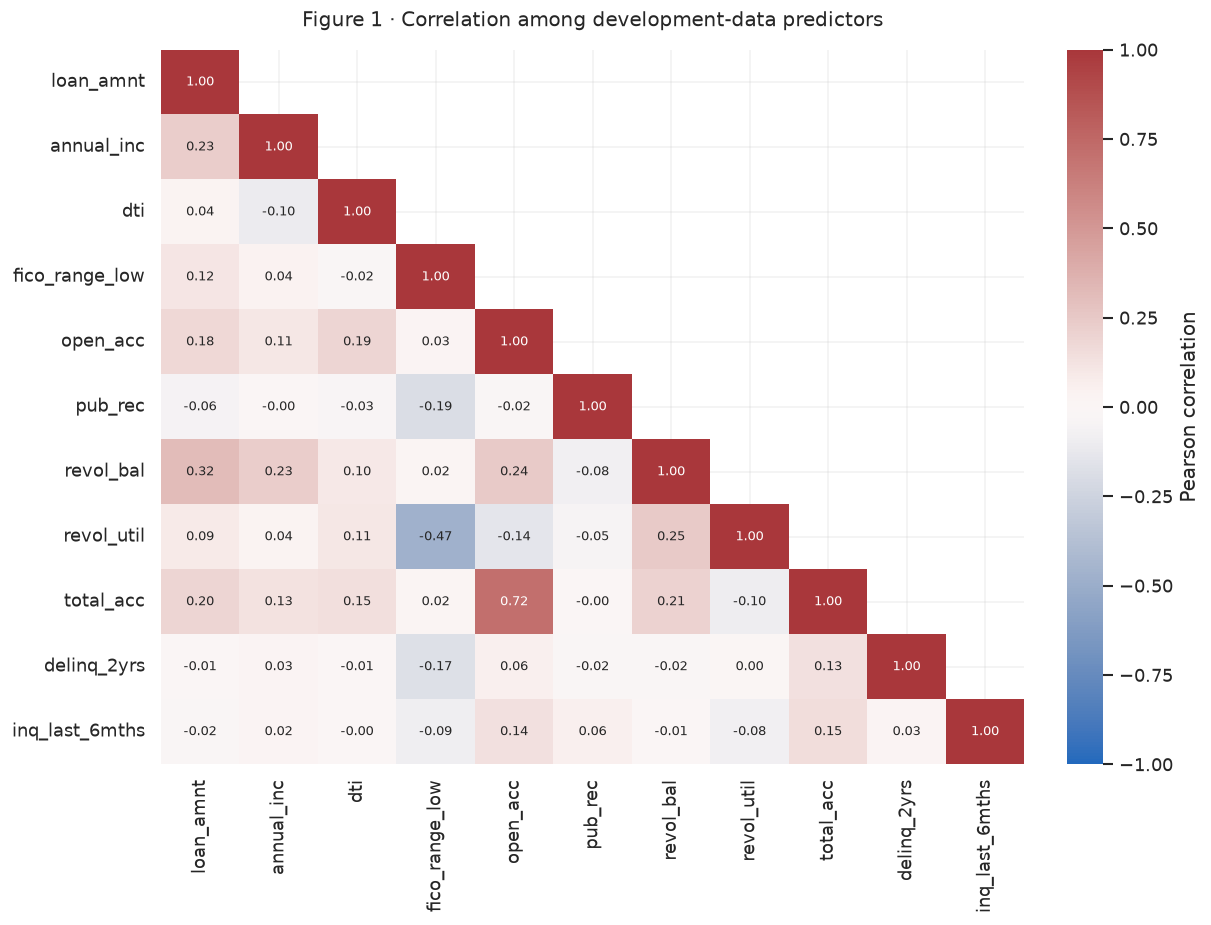

In [6]:
show_table(X_dev.isna().mean().mul(100).rename("Missing (%)").rename_axis("Feature").reset_index().sort_values("Missing (%)",ascending=False).head(6),2)
fig,ax=plt.subplots(figsize=(10,7.6),layout="constrained")
sns.heatmap(X_dev[NUMERIC].corr(),mask=np.triu(np.ones((len(NUMERIC),len(NUMERIC)),dtype=bool),k=1),
    vmin=-1,vmax=1,center=0,cmap="vlag",annot=True,fmt=".2f",annot_kws={"fontsize":8},ax=ax,
    cbar_kws={"label":"Pearson correlation"})
ax.set_title("Figure 1 · Correlation among development-data predictors",pad=14)
finish(fig,"figure_1_predictor_correlation")

## 4. Forward and Backward Selection

Forward selection starts with an empty model and adds the single best predictor at each step. Backward selection starts with all 15 features and drops the weakest one step by step. Crucially, both methods use cross-validated RMSE not training error to make these decisions.

### Search Depth and Model Choice
I run both paths completely from a single predictor all the way to the full 15 feature set. To select the final model size, I apply the one-standard-error (1-SE) rule: locate the lowest mean CV RMSE, then pick the simplest model on that path whose error falls within one estimated standard error of that minimum. This represents a practical preference for simpler models rather than a strict statistical test. Because fold level errors are correlated, this standard error serves as a useful heuristic rather than an exact boundary.

### Search Limitations
Both methods are greedy searches. A full forward path over $p$ features evaluates at most $p(p+1)/2$ candidate models, skipping the exhaustive $2^p - 1$ subset search. For example, if four features are added in the sequence A $\rightarrow$ B $\rightarrow$ C $\rightarrow$ D, the search skips combinations like BC, BD, CD, ACD, and BCD entirely. As a result, strong feature combinations can potentially be missed.

### Computational Efficiency
To keep the search computationally feasible, I cache the transformed design matrices for each fold:
* **Strict Fold Isolation:** Each imputer, encoder, and scaler is fit strictly on that fold's training split.
* **Pipeline Validity:** Because all preprocessing is performed feature by feature, slicing the relevant cached columns is mathematically equivalent to running the entire pipeline from scratch for each subset.
* **No Data Leakage:** No target based selection or filtering happens prior to split generation.

Forward:  1 features | CV RMSE 4.4078
Forward:  2 features | CV RMSE 3.9987
Forward:  3 features | CV RMSE 3.8976
Forward:  4 features | CV RMSE 3.8336
Forward:  5 features | CV RMSE 3.8051
Forward:  6 features | CV RMSE 3.7722
Forward:  7 features | CV RMSE 3.7577
Forward:  8 features | CV RMSE 3.7441
Forward:  9 features | CV RMSE 3.7369
Forward: 10 features | CV RMSE 3.7315
Forward: 11 features | CV RMSE 3.7277
Forward: 12 features | CV RMSE 3.7257
Forward: 13 features | CV RMSE 3.7238
Forward: 14 features | CV RMSE 3.7218
Forward: 15 features | CV RMSE 3.7221
Backward: 14 features | CV RMSE 3.7218
Backward: 13 features | CV RMSE 3.7238
Backward: 12 features | CV RMSE 3.7257
Backward: 11 features | CV RMSE 3.7277
Backward: 10 features | CV RMSE 3.7315
Backward:  9 features | CV RMSE 3.7369
Backward:  8 features | CV RMSE 3.7441
Backward:  7 features | CV RMSE 3.7577
Backward:  6 features | CV RMSE 3.7722
Backward:  5 features | CV RMSE 3.8051
Backward:  4 features | CV RMSE 3.8336
B

Method,Feature count,CV RMSE,Selected features
Forward,9,3.7369,"dti, fico_range_low, revol_bal, revol_util, total_acc, inq_last_6mths, term, home_ownership, purpose"
Backward,9,3.7369,"dti, fico_range_low, revol_bal, revol_util, total_acc, inq_last_6mths, term, home_ownership, purpose"


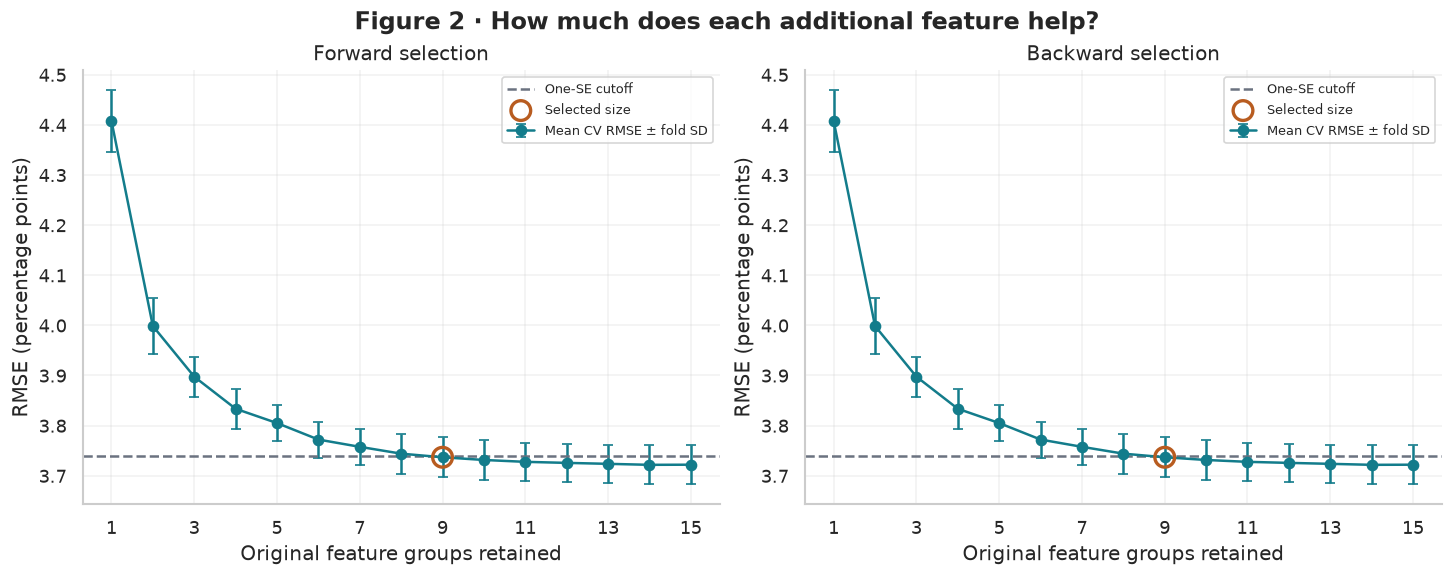

In [7]:
fold_cache=[]
for train_pos,valid_pos in cv_splits:
    prepare=make_preprocessor(numeric_scale=False,scale_all=True)
    train_matrix=prepare.fit_transform(X_dev.iloc[train_pos],y_dev.iloc[train_pos])
    valid_matrix=prepare.transform(X_dev.iloc[valid_pos])
    names=prepare.get_feature_names_out()
    group_columns={feature:np.flatnonzero(np.array([n.startswith(f"g{i:02d}__") for n in names]))
                   for i,feature in enumerate(FEATURES)}
    assert all(len(v)>0 for v in group_columns.values())
    fold_cache.append((train_matrix,valid_matrix,y_dev.iloc[train_pos].to_numpy(),
                       y_dev.iloc[valid_pos].to_numpy(),group_columns))

subset_cache={}
def score_subset(columns):
    key=tuple(c for c in FEATURES if c in columns)
    if key not in subset_cache:
        losses=[];train_losses=[]
        for A,B,ya,yb,groups in fold_cache:
            positions=np.concatenate([groups[c] for c in key])
            model=LinearRegression().fit(A[:,positions],ya)
            losses.append(rmse(yb,model.predict(B[:,positions])))
            train_losses.append(rmse(ya,model.predict(A[:,positions])))
        subset_cache[key]={"Features":key,"Feature count":len(key),"CV RMSE":float(np.mean(losses)),
            "Fold SD":float(np.std(losses,ddof=1)),"CV training RMSE":float(np.mean(train_losses))}
    return subset_cache[key].copy()

forward_rows=[];chosen=[]
while len(chosen)<len(FEATURES):
    candidates=[score_subset(chosen+[c]) for c in FEATURES if c not in chosen]
    best=min(candidates,key=lambda row:(row["CV RMSE"],row["Features"]))
    chosen=list(best["Features"]);forward_rows.append(best)
    print(f"Forward: {len(chosen):2d} features | CV RMSE {best['CV RMSE']:.4f}",flush=True)

backward_rows=[score_subset(FEATURES)];chosen=FEATURES.copy()
while len(chosen)>1:
    candidates=[score_subset([f for f in chosen if f!=c]) for c in chosen]
    best=min(candidates,key=lambda row:(row["CV RMSE"],row["Features"]))
    chosen=list(best["Features"]);backward_rows.append(best)
    print(f"Backward: {len(chosen):2d} features | CV RMSE {best['CV RMSE']:.4f}",flush=True)

forward_path=pd.DataFrame(forward_rows).sort_values("Feature count")
backward_path=pd.DataFrame(backward_rows).sort_values("Feature count")
def select_size(path):
    best=path.loc[path["CV RMSE"].idxmin()]
    limit=best["CV RMSE"]+best["Fold SD"]/np.sqrt(CV_FOLDS)
    selected=path.loc[path["CV RMSE"].le(limit)].sort_values("Feature count").iloc[0]
    return selected,float(limit)
forward_choice,forward_limit=select_size(forward_path)
backward_choice,backward_limit=select_size(backward_path)
selection=pd.DataFrame([{"Method":name,"Feature count":int(row["Feature count"]),
    "CV RMSE":row["CV RMSE"],"Selected features":", ".join(row["Features"])}
    for name,row in [("Forward",forward_choice),("Backward",backward_choice)]])
show_table(selection,4)
for name,path in [("forward",forward_path),("backward",backward_path)]:
    path.to_csv(OUTPUT_DIR/f"{name}_selection_path.csv",index=False)
selection.to_csv(OUTPUT_DIR/"selected_feature_sets.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
for ax,path,choice,limit,title in [(axes[0],forward_path,forward_choice,forward_limit,"Forward selection"),
                                  (axes[1],backward_path,backward_choice,backward_limit,"Backward selection")]:
    ax.errorbar(path["Feature count"],path["CV RMSE"],yerr=path["Fold SD"],fmt="o-",color=TEAL,capsize=3,label="Mean CV RMSE ± fold SD")
    ax.axhline(limit,color=GRAY,ls="--",label="One-SE cutoff")
    ax.scatter(choice["Feature count"],choice["CV RMSE"],s=140,facecolors="none",edgecolors=ORANGE,lw=2,label="Selected size",zorder=5)
    ax.set(title=title,xlabel="Original feature groups retained",ylabel="RMSE (percentage points)",xticks=[1,3,5,7,9,11,13,15])
    ax.legend(fontsize=8)
fig.suptitle("Figure 2 · How much does each additional feature help?",fontweight="bold")
finish(fig,"figure_2_selection_paths")

## 5. PCR and Partial Least Squares

PCR first identifies directions that capture variation among the predictors, then regresses interest rate on those retained component scores. Because PCA doesn't look at the interest rate when constructing these components, a low-variance direction could still carry important pricing information. For that reason, explained predictor variance alone shouldn't determine the final component count.

PLSR, on the other hand, considers both the predictors and the target to build components, actively seeking covariance with the outcome. While this often improves predictive efficiency, it can also increase the risk of fitting noise. I tune the number of components for both methods using the exact same cross-validation folds as the other models.

### Preprocessing and Scaling
Both methods handle imputation, one-hot encoding, and standardization directly inside the pipeline:
* **Standardization:** I scale all features—including one-hot encoded columns—so that variables with large units (like dollar amounts) don't artificially dominate the principal components.
* **Pipeline Settings:** I set `scale=False` within PLSR because the pipeline already standardizes the predictors. PLSR still performs its standard centering on both $X$ and $y$.

### Mathematical Note on PCA and Covariance
For a centered matrix $X_c$ with $n$ samples, the sample covariance matrix is calculated as:

$$\frac{X_c^T X_c}{n - 1}$$

Note that the denominator depends on the sample size $n$, not the feature count $p$. 

Finally, retaining all non-zero PCA components yields the exact same fitted linear predictions as standard OLS (up to numerical precision). Dimensionality reduction only occurs once you start dropping components.

Tuning PCR with [1, 2, 5, 10, 15, 20]
Tuning PLSR with [1, 2, 5, 10, 15, 20]


Method,Components,CV RMSE,Fold SD,CV training RMSE
PCR,1,4.8358,0.0542,4.8358
PCR,2,4.5553,0.0588,4.5548
PCR,5,4.4860,0.0592,4.4850
PCR,10,4.3656,0.0596,4.3626
PCR,15,4.2214,0.0171,4.2168
PCR,20,4.1033,0.0487,4.0905
PLSR,1,3.8385,0.0426,3.8323
PLSR,2,3.7356,0.0372,3.7281
PLSR,5,3.7224,0.0394,3.7147
PLSR,10,3.7222,0.0387,3.7143


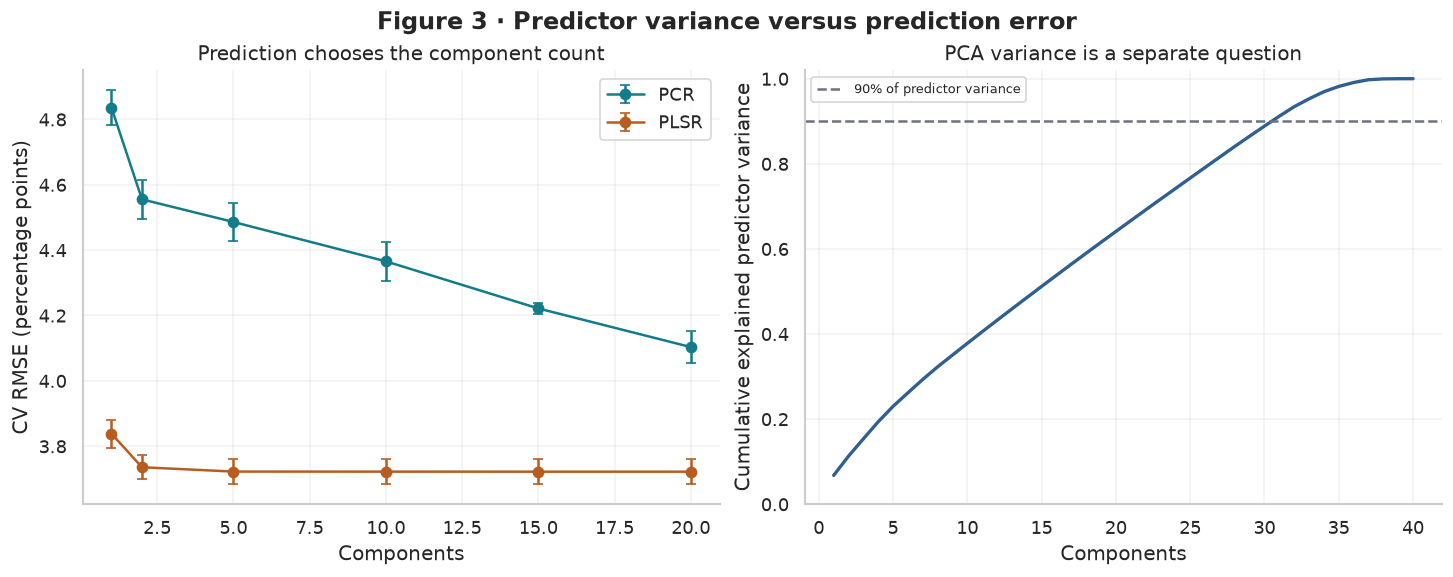

In [8]:
minimum_width=min(A.shape[1] for A,_,_,_,_ in fold_cache)
component_grid=[k for k in [1,2,5,10,15,20] if k<=minimum_width and k<min(len(a) for a,_ in cv_splits)]
if not component_grid: raise ValueError("No feasible component counts.")
pcr=Pipeline([("prepare",make_preprocessor(numeric_scale=False,scale_all=True)),
              ("reduce",PCA(svd_solver="full")),("model",LinearRegression())])
pls=Pipeline([("prepare",make_preprocessor(numeric_scale=False,scale_all=True)),
              ("model",PLSRegression(scale=False,max_iter=1000,tol=1e-6))])
searches={}
component_rows=[]
for name,model,param in [("PCR",pcr,"reduce__n_components"),("PLSR",pls,"model__n_components")]:
    print("Tuning",name,"with",component_grid,flush=True)
    search=GridSearchCV(model,{param:component_grid},scoring="neg_root_mean_squared_error",cv=cv_splits,
        n_jobs=N_JOBS,return_train_score=True,error_score="raise").fit(X_dev,y_dev)
    searches[name]=search
    for i,parameters in enumerate(search.cv_results_["params"]):
        fold_errors=[-search.cv_results_[f"split{fold}_test_score"][i] for fold in range(CV_FOLDS)]
        component_rows.append({"Method":name,"Components":parameters[param],
            "CV RMSE":float(np.mean(fold_errors)),"Fold SD":float(np.std(fold_errors,ddof=1)),
            "CV training RMSE":float(-search.cv_results_["mean_train_score"][i])})
component_results=pd.DataFrame(component_rows)
show_table(component_results,4)
component_results.to_csv(OUTPUT_DIR/"component_cv_results.csv",index=False)

diagnostic_prepare=make_preprocessor(numeric_scale=False,scale_all=True)
diagnostic_matrix=diagnostic_prepare.fit_transform(X_dev)
variance_pca=PCA(svd_solver="full").fit(diagnostic_matrix)
fig,axes=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
for name,color in [("PCR",TEAL),("PLSR",ORANGE)]:
    rows=component_results.loc[component_results.Method.eq(name)]
    axes[0].errorbar(rows.Components,rows["CV RMSE"],yerr=rows["Fold SD"],fmt="o-",color=color,capsize=3,label=name)
axes[0].set(title="Prediction chooses the component count",xlabel="Components",ylabel="CV RMSE (percentage points)")
axes[0].legend()
axes[1].plot(np.arange(1,len(variance_pca.explained_variance_ratio_)+1),np.cumsum(variance_pca.explained_variance_ratio_),color=BLUE,lw=2)
axes[1].axhline(.9,color=GRAY,ls="--",label="90% of predictor variance")
axes[1].set(title="PCA variance is a separate question",xlabel="Components",ylabel="Cumulative explained predictor variance",ylim=(0,1.02))
axes[1].legend(fontsize=8)
fig.suptitle("Figure 3 · Predictor variance versus prediction error",fontweight="bold")
finish(fig,"figure_3_components")

## 6. Freeze the Comparison, Then Evaluate

With the two stepwise model sizes and two component counts now fixed, I compare their CV RMSE against both the full feature OLS model and a mean only baseline. The model with the lowest CV RMSE will be selected for the main interpretation. While the test set table includes all prespecified approaches to see whether CV performance carries over, I will not adjust the chosen model after viewing those results.

### Methodological Considerations
* **Selection Bias in CV:** Searching across many candidate subsets naturally introduces selection bias, making the winning model's CV error somewhat optimistic. The spread across folds should not be interpreted as a confidence interval for the overall selection process a nested CV setup would be required for a rigorous evaluation of the selection procedure itself.
* **Statistical Inference:** Standard coefficient $p$-values computed after stepwise selection fail to account for the greedy search process. As a result, I avoid using them as evidence of statistical significance.

Selected using development CV only: PLSR


Model,CV RMSE,Training RMSE,Test RMSE,Test MAE,Test R2
All-feature OLS,3.7221,3.7149,3.8022,2.8615,0.3976
Forward selection,3.7369,3.7314,3.8242,2.8807,0.3906
Backward selection,3.7369,3.7314,3.8242,2.8807,0.3906
PCR,4.1033,4.0851,4.1546,3.1396,0.2807
PLSR,3.7221,3.7149,3.8022,2.8615,0.3976
Mean baseline,4.8358,4.8359,4.8988,3.8346,-0.0001


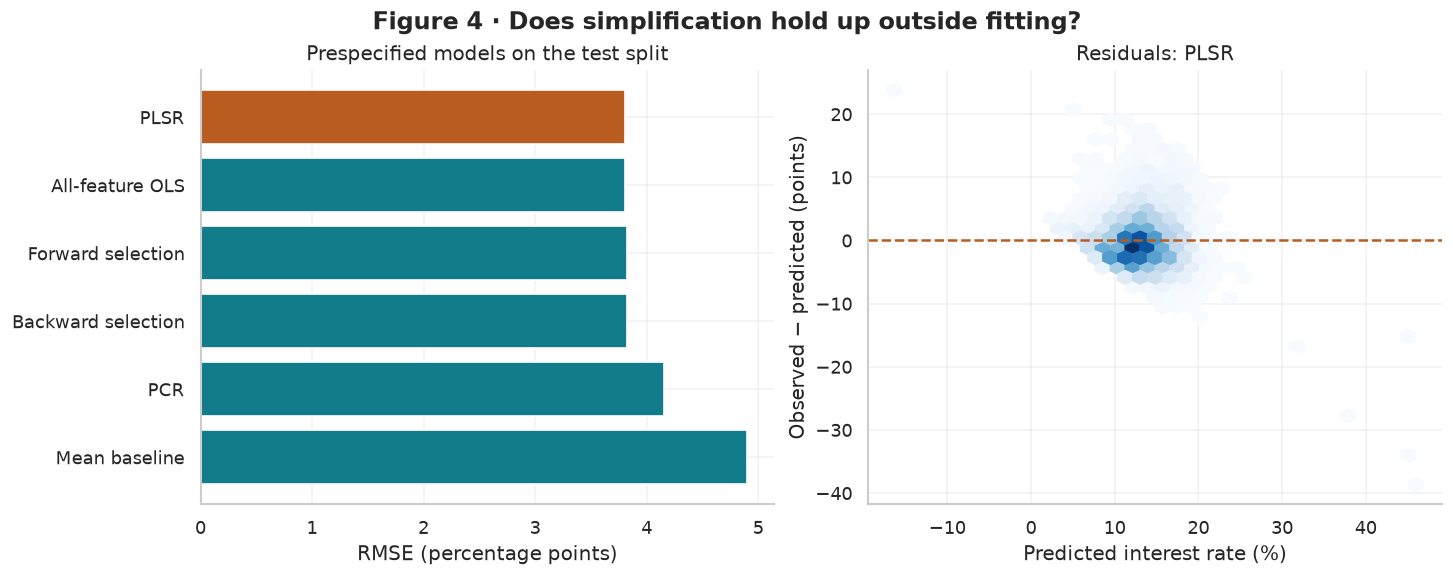

In [9]:
def linear_model(columns):
    return Pipeline([("prepare",make_preprocessor(columns,numeric_scale=False,scale_all=True)),("model",LinearRegression())])
fitted={"All-feature OLS":linear_model(FEATURES).fit(X_dev,y_dev),
    "Forward selection":linear_model(forward_choice["Features"]).fit(X_dev,y_dev),
    "Backward selection":linear_model(backward_choice["Features"]).fit(X_dev,y_dev),
    "PCR":searches["PCR"].best_estimator_,"PLSR":searches["PLSR"].best_estimator_}
mean_model=Pipeline([("prepare",make_preprocessor()),("model",DummyRegressor(strategy="mean"))])
mean_cv=cross_validate(mean_model,X_dev,y_dev,cv=cv_splits,scoring="neg_root_mean_squared_error",error_score="raise")
fitted["Mean baseline"]=mean_model.fit(X_dev,y_dev)
cv_rows=[{"Model":"All-feature OLS","CV RMSE":score_subset(FEATURES)["CV RMSE"]},
    {"Model":"Forward selection","CV RMSE":float(forward_choice["CV RMSE"])},
    {"Model":"Backward selection","CV RMSE":float(backward_choice["CV RMSE"])},
    *[{"Model":name,"CV RMSE":float(-search.best_score_)} for name,search in searches.items()],
    {"Model":"Mean baseline","CV RMSE":float(-mean_cv["test_score"].mean())}]
cv_comparison=pd.DataFrame(cv_rows)
selected_name=cv_comparison.loc[cv_comparison.Model.ne("Mean baseline")].sort_values("CV RMSE",kind="stable").iloc[0].Model
print("Selected using development CV only:",selected_name)
test_results=pd.DataFrame([regression_metrics(name,model,X_dev,y_dev,X_test,y_test) for name,model in fitted.items()]).merge(cv_comparison,on="Model")
show_table(test_results[["Model","CV RMSE","Training RMSE","Test RMSE","Test MAE","Test R2"]],4)
test_results.to_csv(OUTPUT_DIR/"test_metrics.csv",index=False)
pred=np.asarray(fitted[selected_name].predict(X_test)).ravel()
pd.DataFrame({"source_row":loans.loc[X_test.index,"source_row"].to_numpy(),"observed_interest_rate":y_test.to_numpy(),
    "predicted_interest_rate":pred}).to_csv(OUTPUT_DIR/"test_predictions.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.7),layout="constrained")
view=test_results.sort_values("Test RMSE",ascending=False)
axes[0].barh(view.Model,view["Test RMSE"],color=[ORANGE if name==selected_name else TEAL for name in view.Model])
axes[0].set(title="Prespecified models on the test split",xlabel="RMSE (percentage points)")
axes[1].hexbin(pred,y_test.to_numpy()-pred,gridsize=35,mincnt=1,cmap="Blues")
axes[1].axhline(0,color=ORANGE,ls="--")
axes[1].set(title=f"Residuals: {selected_name}",xlabel="Predicted interest rate (%)",ylabel="Observed − predicted (points)")
fig.suptitle("Figure 4 · Does simplification hold up outside fitting?",fontweight="bold")
finish(fig,"figure_4_test_comparison")

## 7. What I Learned, Limits, and Next Steps

The summary paragraph below is dynamically generated from this run. I will retain the numerical findings supported by the output and add any specific observations I want to bring up for peer review.

In [10]:
chosen=test_results.loc[test_results.Model.eq(selected_name)].iloc[0]
full=test_results.loc[test_results.Model.eq("All-feature OLS")].iloc[0]
takeaway=(f"## Week 3 findings\n\nMy CV comparison selected **{selected_name}**. Its test RMSE was **{chosen['Test RMSE']:.3f} percentage points**, "
    f"compared with **{full['Test RMSE']:.3f}** for all-feature OLS. Its test MAE was {chosen['Test MAE']:.3f} and its R² was {chosen['Test R2']:.3f}. "
    f"Forward selection retained {int(forward_choice['Feature count'])} of the 15 original features; backward selection retained {int(backward_choice['Feature count'])}. "
    f"PCR selected {searches['PCR'].best_params_['reduce__n_components']} components and PLSR selected {searches['PLSR'].best_params_['model__n_components']}.\n\n"
    "What matters to me is the error I give up, if any, in return for a smaller model. A selected feature is not automatically a cause of pricing, and a dropped feature is not automatically irrelevant. "
    "Correlated predictors can substitute for each other, and a different sample may produce a different selection path. "
    "The component plots also separate two ideas: explaining predictor variation and predicting interest rate.\n\n"
    "For Milestone One, I will compare this with Week 2's regularization results using matching split manifests. "
    "I will check selection stability and use later loan vintages before claiming the result holds over time. "
    "This analysis describes accepted-loan pricing; it does not measure default detection.")
display(Markdown(takeaway))

## Week 3 findings

My CV comparison selected **PLSR**. Its test RMSE was **3.802 percentage points**, compared with **3.802** for all-feature OLS. Its test MAE was 2.861 and its R² was 0.398. Forward selection retained 9 of the 15 original features; backward selection retained 9. PCR selected 20 components and PLSR selected 20.

What matters to me is the error I give up, if any, in return for a smaller model. A selected feature is not automatically a cause of pricing, and a dropped feature is not automatically irrelevant. Correlated predictors can substitute for each other, and a different sample may produce a different selection path. The component plots also separate two ideas: explaining predictor variation and predicting interest rate.

For Milestone One, I will compare this with Week 2's regularization results using matching split manifests. I will check selection stability and use later loan vintages before claiming the result holds over time. This analysis describes accepted-loan pricing; it does not measure default detection.

## Week 3 Findings

Cross-validation selected **PLSR** as the top performing model. On the test set, its RMSE came in at **3.802 percentage points**, matching the **3.802** achieved by the full 15 feature OLS baseline. It delivered a test MAE of **2.861** and an $R^2$ of **0.398**. Through the feature selection and dimension reduction pipelines:
* **Forward Selection:** Retained 9 of the 15 original features.
* **Backward Selection:** Retained 9 of the 15 original features.
* **PCR & PLSR:** Both selected 20 components.

### Practical Takeaways
What matters most to me is understanding what predictive accuracy I give up, if any, in exchange for a simpler, lower dimensional model. It is critical not to over interpret the feature selection output:
* **Causality vs. Correlation:** A selected feature is not automatically a causal driver of interest rates, nor is a dropped feature inherently irrelevant. Highly correlated predictors frequently substitute for one another, and a different sample could easily yield a different selection path.
* **Variance Explained vs. Predictive Power:** The component plots help separate two distinct objectives explaining variance within the predictor matrix versus actually predicting the interest rate target.

### Scope and Next Steps
For Milestone One, I will align these results with Week 2's regularization findings using matching split manifests. Before making any claims that these insights hold over time, I need to test selection stability and evaluate performance on later loan vintages. Finally, keep in mind that this analysis specifically models interest rate pricing on accepted loans—it does not evaluate default risk detection.

In [11]:
run_summary={"week":3,"dataset_version":DATASET_VERSION,"sample_rows":len(loans),
    "source_rows":source_info["rows_scanned"],"seed":SEED,"python":sys.version.split()[0],
    "pandas":pd.__version__,"sklearn":sklearn.__version__,
    "sample_source_rows_sha256":hashlib.sha256(loans["source_row"].to_numpy(dtype="int64").tobytes()).hexdigest()}
run_summary.update({"target":"int_rate","selected_model":selected_name,"development_rows":len(y_dev),"test_rows":len(y_test),"forward_features":list(forward_choice["Features"]),"backward_features":list(backward_choice["Features"]),"pcr_components":int(searches["PCR"].best_params_["reduce__n_components"]),"pls_components":int(searches["PLSR"].best_params_["model__n_components"])})
(OUTPUT_DIR/"run_summary.json").write_text(json.dumps(run_summary,indent=2))
(OUTPUT_DIR/"milestone_takeaway.md").write_text(takeaway,encoding="utf-8")
print("Saved figures, tables, settings, and the computed takeaway to",OUTPUT_DIR)

Saved figures, tables, settings, and the computed takeaway to week3_outputs
